# 09 | How reliable are low-count and session-specific SC edges?

**Learning goals:** separate seed-sampling stability from anatomical validity; inspect newly tracked streamlines; compare count thresholds, consensus supports and coupling; preserve the distinction between SC and FC uncertainty.

**Primary FC stability:** notebook 14 recommends 97 distinct frames per session from nonreplacement ten-frame blocks, with complete WM/CSF nuisance refitting. These equal-duration subset ranges are conditional stability summaries, not full-run confidence intervals. The observed full-run points remain unchanged. Notebooks 10/11/13 retain earlier bootstrap, matching and mechanism analyses as sensitivities. See `config/PRIMARY_FC_RESAMPLING.md`. **Current SC policy:** graphs, network means and simulations use each session's 16/20 consensus with mean counts per 10,000 attempted seeds. Primary paired coupling uses the 823-edge intersection with session-specific weights. See `config/PRIMARY_SC.md`. Historical seed-160 diagnostics in notebooks 07/08 remain sensitivity analyses; notebook 09 supplies the reliability evidence. Notebook 10 quantifies joint seed/FC sampling under this policy, including matched designs and support reselection. Notebook 11 extends the full-run branch to paired nuisance refits; notebook 12 integrates all clinical/context fields with network uncertainty. Notebook 13 diagnoses PCA-training shifts and compares nonreplacement blocks at matched distinct counts and 80% retention. The rule is post hoc and does not validate anatomy or a surgical/cognitive effect.

In [1]:
from pathlib import Path
import os, sys, json
root = Path.cwd() if (Path.cwd()/"pyproject.toml").exists() else Path.cwd().parent
os.environ.setdefault("MPLCONFIGDIR", str(root/".cache/matplotlib"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown, Image
from pat16 import ROOT, DATA, RESULTS, SESSIONS
from pat16.connectivity import labels
from pat16.primary_sc import load_weights
nodes = pd.read_csv(RESULTS/"nodes.csv")
summary = json.loads((RESULTS/"summary.json").read_text())
plt.rcParams.update({"figure.figsize": (9,4), "font.size": 10})


## What is repeated, and what stays fixed?
Twenty **new tractography runs per session**, each with 30,000 seed locations, use independent RNG initializations (17000–17019 pre-op; 18000–18019 post-op). CSD directions, diffusion data, masks, geometry, stopping and endpoint rules stay fixed. This is random seed-location variation in deterministic tracking, **not resampling the original tractogram**, new diffusion scans, diffusion-noise bootstrapping, registration variation or anatomical validation.

The original tracker used float64 CSD coefficients but saved a float32 cache. The identical high-shell model/response is refitted once in float64; separate seed-160 replays must reproduce both original count matrices exactly. Original SC, FC, nuisance fits and previous sensitivity outputs are retained. All 4,950 cortical pairs are evaluated, including edges absent from both original runs. “Session-specific” means a particular reconstruction's support, not proven tract loss/gain.

preop {'seed': 160, 'seconds': 12.304332971572876, 'exact_count_matrix_reproduction': True, 'max_count_difference': 0, 'length_filtered_streamlines': 26488, 'original_length_filtered_streamlines': 26488, 'max_abs_coeff_difference_from_float32_cache': 4.96755754308964e-08}
postop {'seed': 160, 'seconds': 13.339606046676636, 'exact_count_matrix_reproduction': True, 'max_count_difference': 0, 'length_filtered_streamlines': 26421, 'original_length_filtered_streamlines': 26421, 'max_abs_coeff_difference_from_float32_cache': 2.9794408606953482e-08}


,session,baseline_group,baseline_count_bin,edges,median_detection_fraction,mean_detection_fraction,ever_detected_edges,detected_ge80_edges,never_detected_edges,median_mean_count,median_count_cv
0,preop,shared,all,1071,1.00,0.897012,1069,890,2,5.100,0.390197
6,preop,pre_only,all,444,0.80,0.683896,439,231,5,1.550,0.788101
12,preop,post_only,all,488,0.10,0.211270,342,24,146,0.100,2.011580
14,preop,absent_both,all,2947,0.00,0.050780,731,15,2216,0.000,2.615742
16,postop,shared,all,1071,1.00,0.897152,1068,891,3,5.750,0.384509
22,postop,pre_only,all,444,0.15,0.248311,322,31,122,0.150,1.777047
24,postop,post_only,all,488,0.70,0.640061,478,216,10,1.125,0.869422
30,postop,absent_both,all,2947,0.00,0.055633,820,25,2127,0.000,3.077935


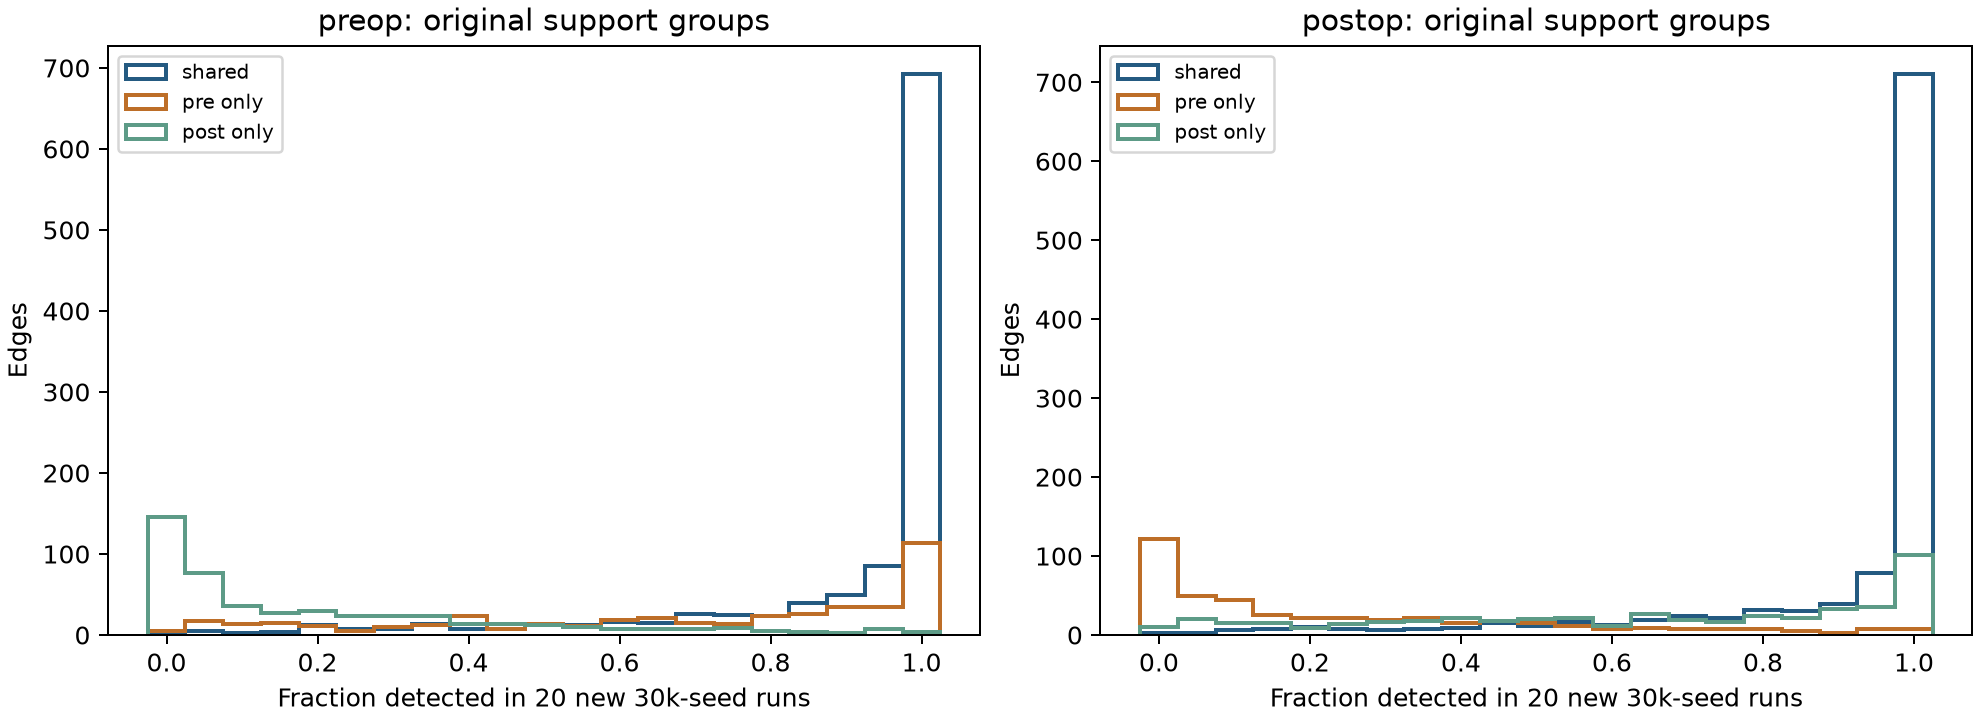

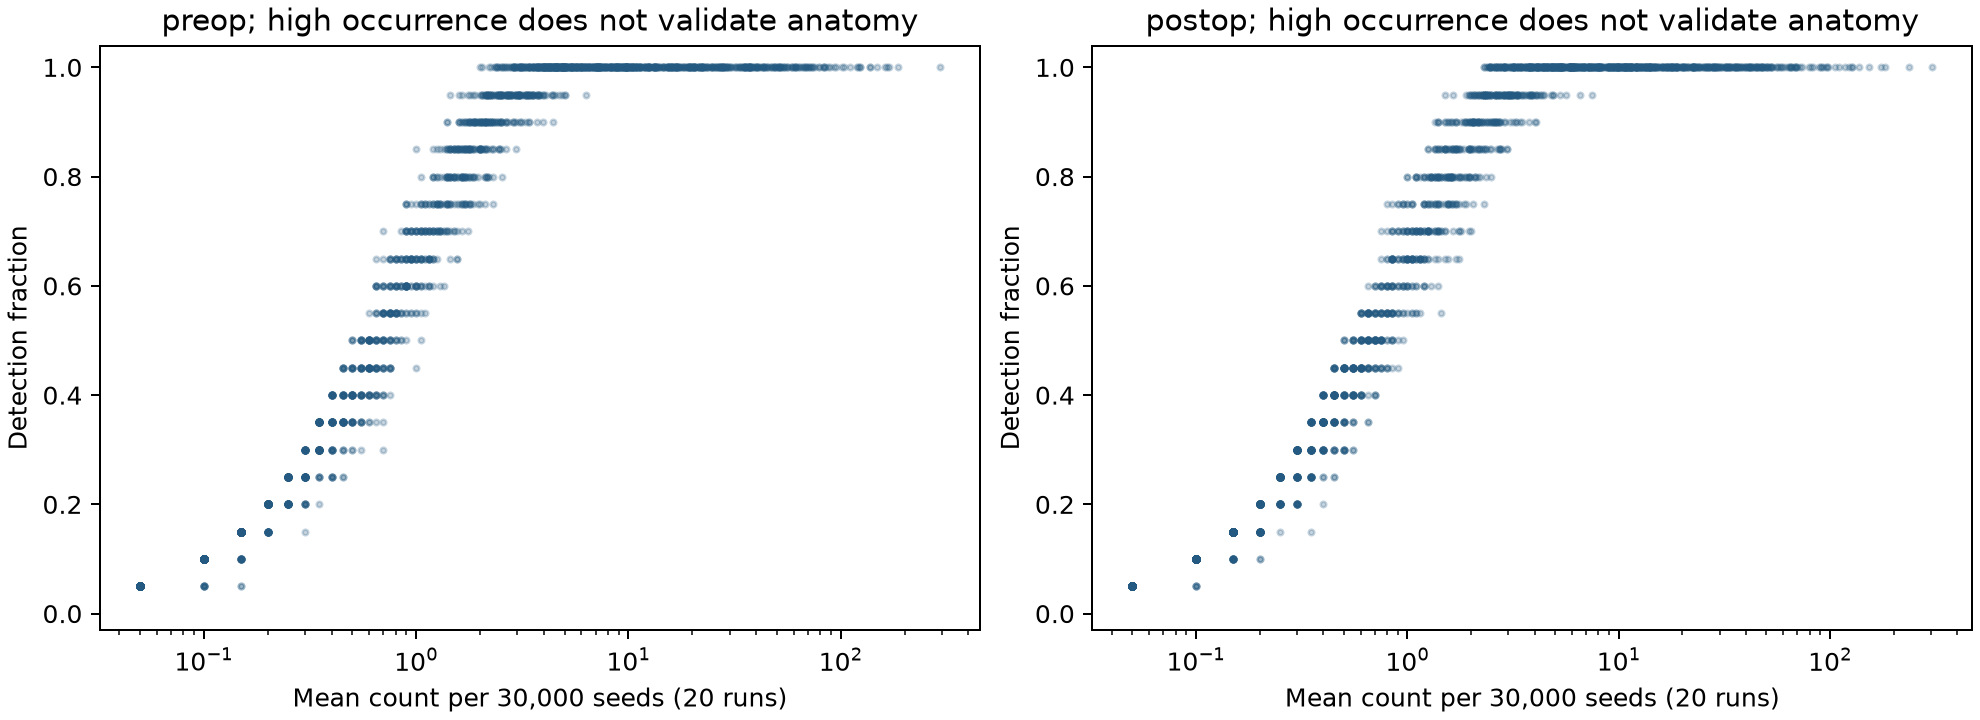

In [2]:
from pat16.tract_repeats import OUT as REL, REPEATS, SEEDS
from pat16.sc_reliability import load, threshold_weights, consensus_weights, evaluate, THRESHOLDS, CONSENSUS
ri,rj,baseline_sc,repeat_sc,reliability_fc=load()
reliable_edges=pd.read_csv(REL/"edges.csv")
reliability_summary=pd.read_csv(REL/"edge_reliability_summary.csv")
fixed_reliability=pd.read_csv(REL/"fixed_coupling.csv")
repeat_summary=pd.read_csv(REL/"repeat_coupling_summary.csv")
for session in SESSIONS:
    print(session,json.loads((REL/session/"baseline_replay.json").read_text()))
display(reliability_summary[reliability_summary.baseline_count_bin=="all"])
display(Image(filename=str(RESULTS/"figures/sc_repeat_detection.png")))
display(Image(filename=str(RESULTS/"figures/sc_repeat_counts.png")))

## Inspect occurrence and count variability for any edge
Occurrence at k is the fraction of 20 runs with **count ≥ k**, at the same 30,000-seed budget (resolution 0.05). Count SD/CV include zero-count runs; all-zero means have undefined CV and are omitted from median CV. Original singletons have median occurrence 0.55/0.50 (pre/post), versus 1.00/1.00 for original counts ≥10. The original pre-only/post-only labels are fixed; inspect whether those edges reappear in the opposite session. No hits in 20 runs is limited sampling evidence, not confirmed anatomical absence.

Start with edge 21–42, the largest positive original reversal term: it appears in only 3/20 pre-op and 2/20 post-op repeats (mean count 0.15 in each session). Compare it with the largest negative term 16–35, and with high-count edges. Atlas centroids/labels do not validate an individual connection. Thresholds apply to individual runs, not to the pooled count over 600,000 seeds.

,value
node_i,21
node_j,42
label_i,7Networks_LH_DorsAttn_Post_6
label_j,7Networks_LH_Default_PFC_1
baseline_group,pre_only
repeat_consensus80_class,neither
original_reversal_term,0.002773


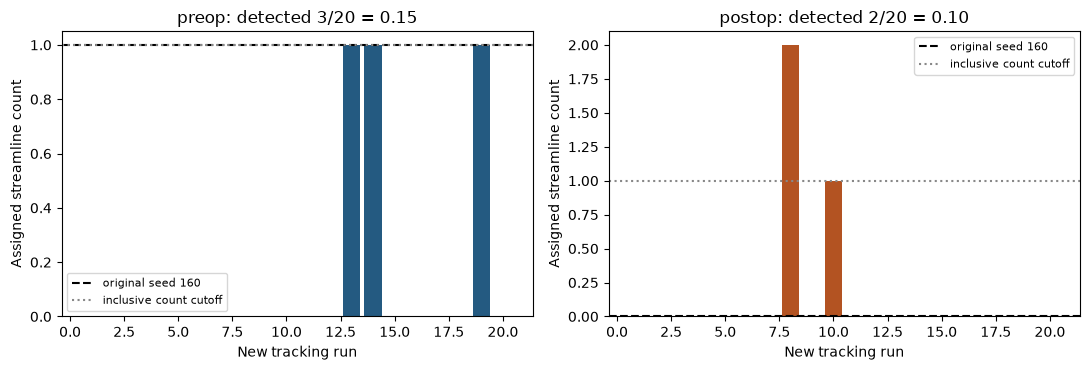

interactive(children=(IntSlider(value=21, continuous_update=False, description='node_a', min=1), IntSlider(val…

<function __main__.inspect_reliability(node_a=21, node_b=42, minimum_count=1)>

In [3]:
def inspect_reliability(node_a=21,node_b=42,minimum_count=1):
    if node_a==node_b:
        print("Choose two different parcels.");return
    a,b=sorted([node_a,node_b]);idx=int(np.flatnonzero((ri==a-1)&(rj==b-1))[0]);row=reliable_edges.iloc[idx]
    display(row[["node_i","node_j","label_i","label_j","baseline_group","repeat_consensus80_class","original_reversal_term"]].to_frame("value"))
    fig,axs=plt.subplots(1,2,figsize=(11,3.8))
    for t,session in enumerate(SESSIONS):
        vals=repeat_sc[t,:,idx];freq=float((vals>=minimum_count).mean())
        axs[t].bar(np.arange(1,21),vals,color="#245a81" if t==0 else "#b35322")
        axs[t].axhline(baseline_sc[t,idx],color="black",ls="--",label="original seed 160")
        axs[t].axhline(minimum_count,color="#888",ls=":",label="inclusive count cutoff")
        axs[t].set_title(f"{session}: detected {int((vals>=minimum_count).sum())}/20 = {freq:.2f}")
        axs[t].set_xlabel("New tracking run");axs[t].set_ylabel("Assigned streamline count");axs[t].legend(fontsize=8)
    plt.tight_layout();plt.show();plt.close(fig)
widgets.interact(inspect_reliability,node_a=widgets.IntSlider(min=1,max=100,value=21,continuous_update=False),node_b=widgets.IntSlider(min=1,max=100,value=42,continuous_update=False),minimum_count=widgets.Dropdown(options=THRESHOLDS,value=1))

## Count thresholds change the ranked edge universe
We test inclusive minimum counts **1, 2, 3, 5, 10, 20** without choosing a cutoff from its coupling sign. “Own” thresholds each session separately; “common” retains the intersection at that cutoff with each session's own count weights. Measured FC is unchanged; SC-absent edges are excluded, never replaced by FC=0. Every SC/FC rank and denominator is recomputed.

For each threshold, all 20×20 pre/post repeat combinations are considered rather than arbitrarily pairing distinct RNG IDs. The 400 combinations **reuse runs and are dependent**. Empirical ranges and sign fractions describe seed sensitivity conditional on fixed scans/FC, not confidence intervals, probabilities of a surgical effect or 400 independent subjects. At k=1 with own repeated SC, median Δ is −0.00043/+0.02852 for primary/strict, and the original negative-primary/positive-strict pattern occurs in 174/400 combinations. Both empirical ranges cross zero. Thresholding can change both contrast signs while preserving a nonzero strict-minus-primary shift R; these are different questions. Repeated common-support strict median is +0.00579, even though the original common-support strict contrast is negative; a single shared-only result is also seed-conditional.

,threshold,support,pre_edges,post_edges,shared_edges,primary_pre,primary_post,primary_delta,strict_pre,strict_post,strict_delta,reversal_shift
0,1,own,1515,1559,1071,0.210147,0.189426,-0.02072,0.156366,0.16751,0.011144,0.031865


,threshold,support,combinations,reversal_pattern_fraction,primary_delta_median,primary_delta_q025,primary_delta_q975,strict_delta_median,strict_delta_q025,strict_delta_q975,...,reversal_shift_q975,pre_edges_median,pre_edges_q025,pre_edges_q975,post_edges_median,post_edges_q025,post_edges_q975,shared_edges_median,shared_edges_q025,shared_edges_q975
1,1,own,400,0.435,-0.000431,-0.037899,0.033373,0.028519,-0.010901,0.064026,...,0.070431,1519.0,1481.0,1554.0,1548.5,1511.0,1573.0,1067.0,1034.975,1090.025


,method,threshold,consensus_fraction,support,partition,group,retained_union_edges,reversal_term
19,baseline,1,NaN,own,network_pair,Default / SomMot,103,0.012368
18,baseline,1,NaN,own,network_pair,Default / SalVentAttn,129,0.008961
17,baseline,1,NaN,own,network_pair,Default / Limbic,71,0.006439
35,baseline,1,NaN,own,network_pair,Vis / Vis,98,0.006304
33,baseline,1,NaN,own,network_pair,SomMot / SomMot,65,0.006076


interactive(children=(Dropdown(description='minimum_count', options=(1, 2, 3, 5, 10, 20), value=1), Dropdown(d…

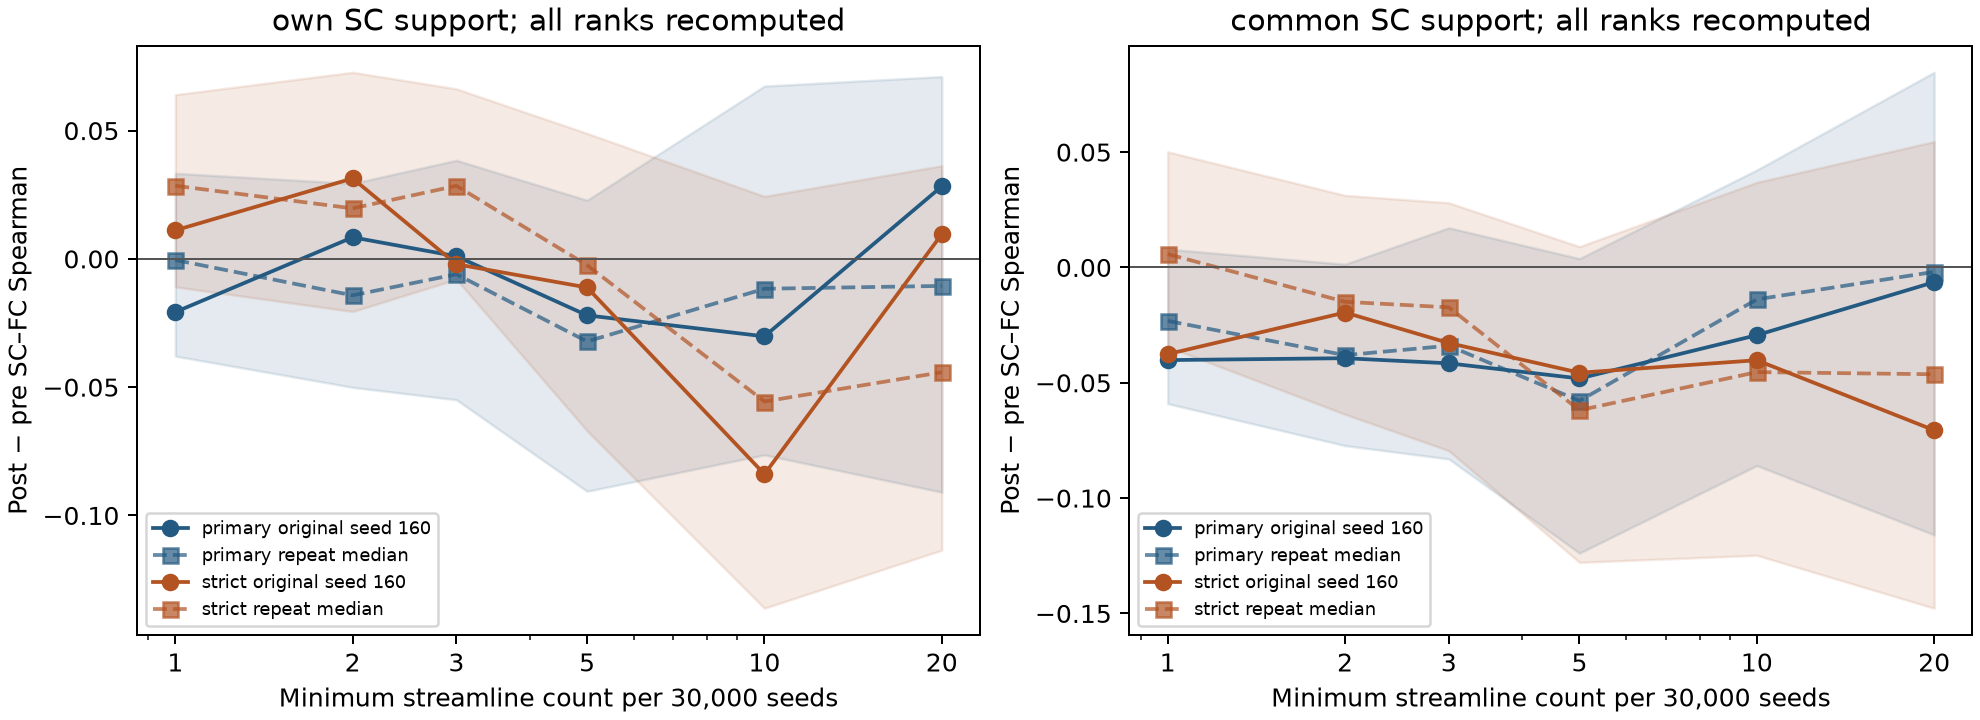

In [4]:
def threshold_browser(minimum_count=1,support="own"):
    a=fixed_reliability[(fixed_reliability.method=="baseline")&(fixed_reliability.threshold==minimum_count)&(fixed_reliability.support==support)]
    b=repeat_summary[(repeat_summary.threshold==minimum_count)&(repeat_summary.support==support)]
    display(a[["threshold","support","pre_edges","post_edges","shared_edges","primary_pre","primary_post","primary_delta","strict_pre","strict_post","strict_delta","reversal_shift"]])
    display(b)
    terms=pd.read_csv(REL/"coupling_contributions.csv")
    terms=terms[(terms.method=="baseline")&(terms.threshold==minimum_count)&(terms.support==support)&(terms.partition=="network_pair")]
    display(terms.sort_values("reversal_term",ascending=False).head(5))
widgets.interact(threshold_browser,minimum_count=widgets.Dropdown(options=THRESHOLDS,value=1),support=widgets.Dropdown(options=["own","common"],value="own"))
display(Image(filename=str(RESULTS/"figures/sc_repeat_coupling.png")))

## Consensus support is another sensitivity analysis
At occurrence fractions 0.5, 0.8, 0.95 or 1.0, retain edges whose per-run count reaches k often enough. SC weights are **mean counts per 30,000 seeds**, not occurrence probabilities or pooled-count thresholds. Compare own versus common consensus supports. Consensus can admit an edge missing from the original run and exclude an edge seen only by chance; it also changes the population and weighting of coupling.

At k=1, 80% own consensus retains 1160/1163 edges and yields primary/strict Δ=−0.00257/+0.02363. Common consensus retains 823 edges and gives −0.04173/−0.03424. Neither validates a directional biological change.

The 80% class “pre-only” only means the post-op frequency is below 0.8; it can still be detected in many post-op runs. A separate inventory flag marks ≥0.8 in one session with 0/20 in the other. Neither proves loss/gain. Mean SC uses all 20 runs and is not independent anatomical validation. The consensus fraction and streamline cutoff are exploratory controls, not calibrated false-positive thresholds.

,pre_edges,post_edges,shared_edges,union_edges,primary_pre,primary_post,primary_delta,strict_pre,strict_post,strict_delta,reversal_shift
0,823,823,823,823,0.188216,0.146488,-0.041728,0.160765,0.126526,-0.034239,0.007489


,method,threshold,consensus_fraction,support,partition,group,retained_union_edges,reversal_term
256,consensus,1,0.8,common,repeat_consensus80,both,823,0.007489
257,consensus,1,0.8,common,repeat_consensus80,neither,0,0.000000
258,consensus,1,0.8,common,repeat_consensus80,post_only,0,0.000000
259,consensus,1,0.8,common,repeat_consensus80,pre_only,0,0.000000


,method,threshold,consensus_fraction,support,partition,group,retained_union_edges,reversal_term
271,consensus,1,0.8,common,network_pair,Default / SomMot,30,0.014555
285,consensus,1,0.8,common,network_pair,SomMot / SomMot,30,0.008555
272,consensus,1,0.8,common,network_pair,Default / Vis,45,0.008165
270,consensus,1,0.8,common,network_pair,Default / SalVentAttn,61,0.007794
264,consensus,1,0.8,common,network_pair,Cont / SalVentAttn,33,0.006940


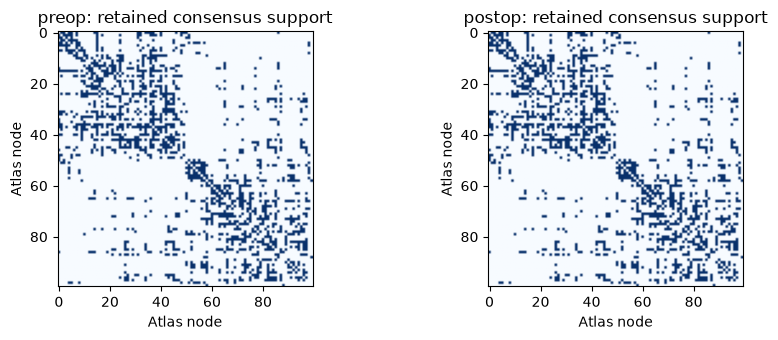

interactive(children=(Dropdown(description='minimum_count', options=(1, 2, 3, 5, 10, 20), value=1), Dropdown(d…

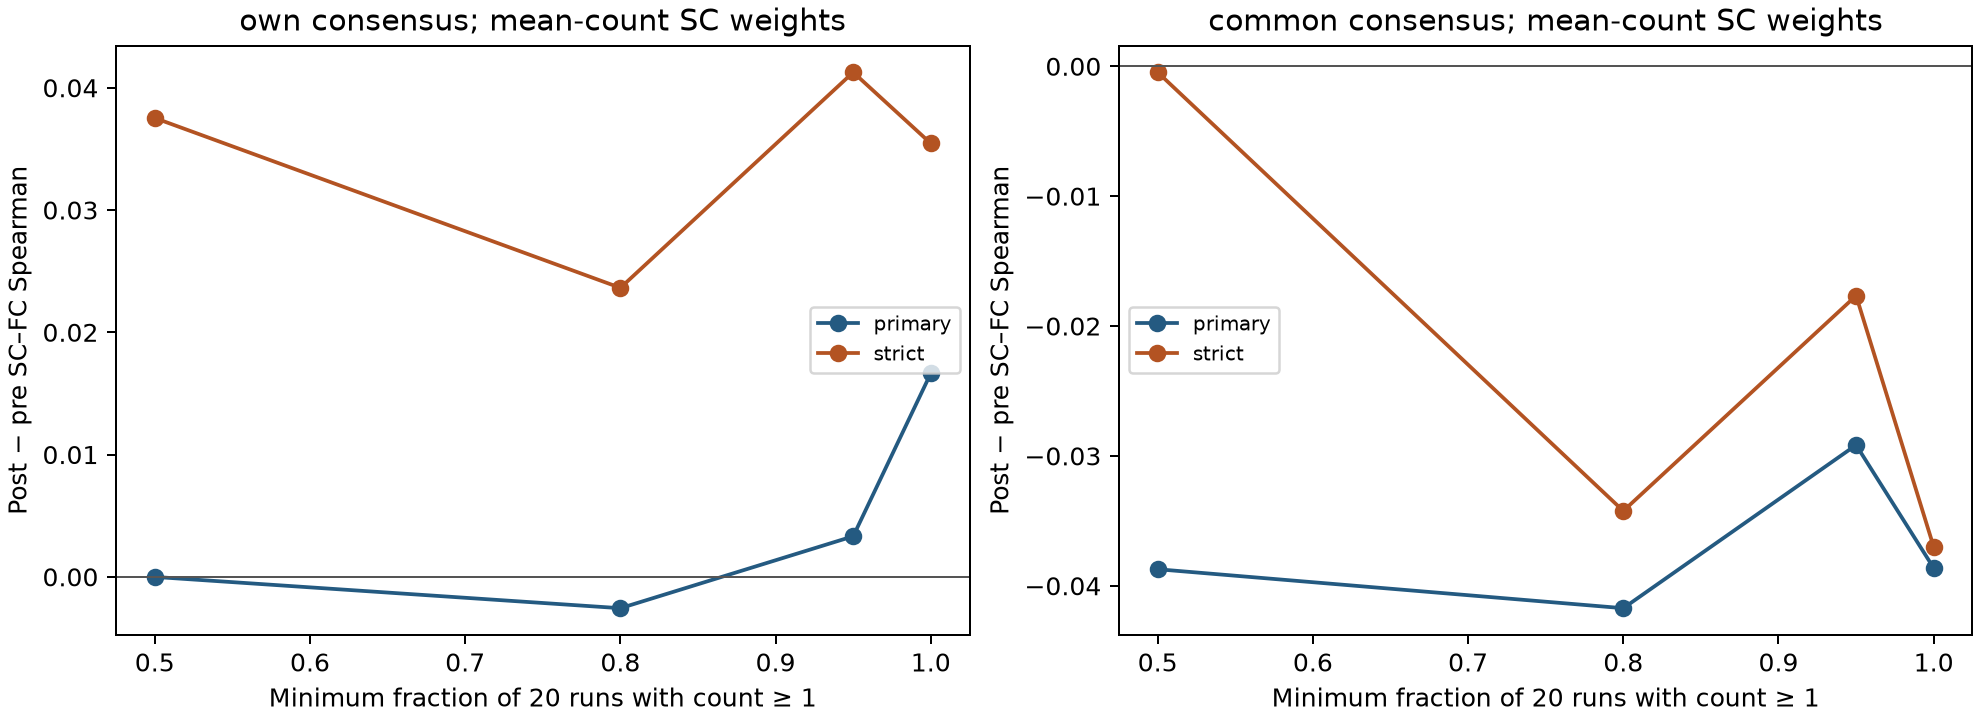

In [5]:
reliability_terms=pd.read_csv(REL/"coupling_contributions.csv")
def consensus_browser(minimum_count=1,occurrence=.8,support="common"):
    w=consensus_weights(repeat_sc,minimum_count,occurrence,support)
    display(pd.DataFrame([evaluate(w,reliability_fc)]))
    selected=reliability_terms[(reliability_terms.method=="consensus")&(reliability_terms.threshold==minimum_count)&np.isclose(reliability_terms.consensus_fraction,occurrence)&(reliability_terms.support==support)]
    display(selected[selected.partition=="repeat_consensus80"])
    display(selected[selected.partition=="network_pair"].sort_values("reversal_term",ascending=False).head(5))
    fig,axs=plt.subplots(1,2,figsize=(9,3.5))
    for t,session in enumerate(SESSIONS):
        mat=np.zeros((100,100));mat[ri,rj]=w[t]>0;mat+=mat.T
        axs[t].imshow(mat,cmap="Blues",vmin=0,vmax=1);axs[t].set_title(session+": retained consensus support");axs[t].set_xlabel("Atlas node");axs[t].set_ylabel("Atlas node")
    plt.tight_layout();plt.show();plt.close(fig)
widgets.interact(consensus_browser,minimum_count=widgets.Dropdown(options=THRESHOLDS,value=1),occurrence=widgets.Dropdown(options=CONSENSUS,value=.8),support=widgets.Dropdown(options=["own","common"],value="common"))
display(Image(filename=str(RESULTS/"figures/sc_repeat_consensus.png")))

## Revisit the original reversal accounting
The original R contributions from notebook 08 can be cross-tabulated by 80% repeat-consensus class without changing those original ranks. These signed terms still sum to the original R. This distinguishes an original “pre-only” edge from an edge that is repeatedly supported in both sessions.

Of 444 original pre-only edges, 322 reappear at least once post-op; 342 of 488 original post-only edges reappear pre-op. Only 31/24 reach ≥80% occurrence in those previously absent sessions. The original pre-only reversal term is concentrated in **207 edges below 80% occurrence in both sessions**, contributing **+0.02412** of the full +0.03186 shift. These are signed cancelling terms, not percentages of neural variance.

The re-ranked terms for new threshold/consensus matrices answer a different question. The browser above exports their network-pair and support contributions as well. Do not subtract original low-count edge terms and call that thresholded coupling: all surviving ranks change.

In [6]:
cross=pd.read_csv(REL/"original_reversal_by_reliability.csv")
display(cross.pivot(index="baseline_group",columns="repeat_consensus80_class",values="edges").fillna(0).astype(int))
display(cross.pivot(index="baseline_group",columns="repeat_consensus80_class",values="original_reversal_term").fillna(0))
print("Original R reconstructed:",cross.original_reversal_term.sum())
for group,other in [("pre_only","postop"),("post_only","preop")]:
    v=reliable_edges[reliable_edges.baseline_group==group]
    print(group,"opposite-session rediscovery:",int((v[other+"_frequency_ge1"]>0).sum()),"of",len(v),"; opposite-session >=80%:",int((v[other+"_frequency_ge1"]>=.8).sum()))

repeat_consensus80_class,both,neither,post_only,pre_only
baseline_group,,,,
absent_both,1,2908,24,14
post_only,17,265,199,7
pre_only,25,207,6,206
shared,780,70,111,110


repeat_consensus80_class,both,neither,post_only,pre_only
baseline_group,,,,
absent_both,0.000000,0.000000,0.000000,0.000000
post_only,0.001382,-0.002987,0.001111,-0.000344
pre_only,-0.002138,0.024117,0.000117,0.002276
shared,0.003934,-0.001649,-0.003252,0.009297


Original R reconstructed: 0.0318647118208333
pre_only opposite-session rediscovery: 322 of 444 ; opposite-session >=80%: 31
post_only opposite-session rediscovery: 342 of 488 ; opposite-session >=80%: 24


## Separate FC sampling from the SC reference
All six earlier matching protocols ×200 saved masks are replayed with full nuisance refitting. Five SC references are held fixed: original own SC at counts ≥1, ≥3, ≥5 and 80% consensus at k=1 under own/common support. The original k=1 results must reproduce notebook 07 exactly. Historical frozen-nuisance analyses remain there.

These spreads vary the selected BOLD frames while holding SC fixed. The earlier repeat plots vary SC seeding while holding FC fixed. **Notebook 10 now crosses whole-run SC bootstrap draws with FC draws under the recommended policy**, including fixed and reselected support. These historical one-source spreads are retained and must not be added to manufacture a joint interval.

,protocol,sc_reference,draws,median,q025,q975,positive_fraction
0,strict_motion,baseline_k1,200,-0.013463,-0.043902,0.014357,0.175
1,strict_motion,baseline_k3,200,-0.016013,-0.052243,0.018921,0.195
2,strict_motion,baseline_k5,200,-0.025514,-0.067903,0.008817,0.080
3,strict_motion,consensus80_common,200,-0.047966,-0.089791,-0.015873,0.000
4,strict_motion,consensus80_own,200,0.000571,-0.032064,0.033864,0.510


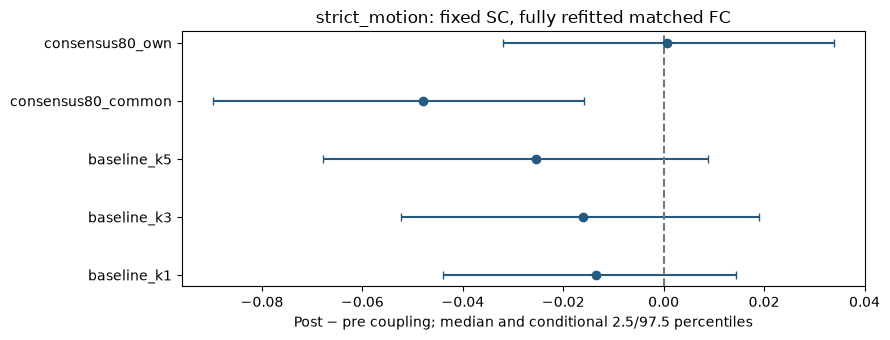

interactive(children=(Dropdown(description='protocol', index=4, options=('primary_duration', 'primary_motion',…

<function __main__.matched_reference(protocol='strict_motion')>

In [7]:
matched_rel=pd.read_csv(REL/"matched_coupling_summary.csv")
def matched_reference(protocol="strict_motion"):
    v=matched_rel[matched_rel.protocol==protocol].reset_index(drop=True)
    display(v)
    fig,ax=plt.subplots(figsize=(9,3.5));y=np.arange(len(v))
    ax.errorbar(v["median"],y,xerr=np.vstack([v["median"]-v.q025,v.q975-v["median"]]),fmt="o",capsize=3,color="#245a81")
    ax.axvline(0,color="#777",ls="--");ax.set_yticks(y,v.sc_reference);ax.set_xlabel("Post − pre coupling; median and conditional 2.5/97.5 percentiles");ax.set_title(protocol+": fixed SC, fully refitted matched FC")
    plt.tight_layout();plt.show();plt.close(fig)
widgets.interact(matched_reference,protocol=widgets.Dropdown(options=matched_rel.protocol.unique().tolist(),value="strict_motion"))

## Conditional repeatability and what remains unknown
Within-session Jaccard measures overlap of thresholded supports; count-rank agreement is computed over all 4,950 edges, including tied zeros. Split-half controls select 80% consensus in the first ten runs and inspect occurrence in the last ten, then reverse the roles. This checks seeding consistency within this model; systematic false positives can repeat, and model, registration, endpoint and acquisition errors are held fixed.

The primary recommendation is now 16/20 consensus with all-run mean counts per 10,000 seeds. Structural graphs use own consensus (1160/1163 edges); paired coupling uses its fixed 823-edge intersection. Original seed-160 and all other count/consensus settings remain sensitivities. The 80% cutoff is pragmatic, not calibrated; it is selected for repeat stability and comparable edge populations, never a desired coupling sign. These results cannot establish tract loss/gain or localize CANTAB/QoL changes. Independent repeated acquisitions, lesion-aware mapping, alternative tracking/model choices and anatomical review would address additional uncertainties.

In [8]:
overlap_rel=pd.read_csv(REL/"within_session_overlap.csv")
display(overlap_rel.groupby(["session","threshold"]).agg(median_Jaccard=("jaccard","median"),q025_Jaccard=("jaccard",lambda x:x.quantile(.025)),q975_Jaccard=("jaccard",lambda x:x.quantile(.975)),median_count_rank=("count_spearman_all_4950_edges","median")))
display(pd.read_csv(REL/"split_half.csv"))
print(json.loads((REL/"summary.json").read_text()))

median_Jaccard  q025_Jaccard  q975_Jaccard  \
session threshold                                               
postop  1                0.693232      0.677522      0.713246   
        2                0.728174      0.708927      0.743520   
        3                0.734171      0.717188      0.750064   
        5                0.746023      0.713492      0.769713   
        10               0.763713      0.731616      0.790915   
        20               0.804302      0.761093      0.850277   
preop   1                0.708615      0.690532      0.723766   
        2                0.727802      0.708629      0.744053   
        3                0.729616      0.710050      0.749785   
        5                0.733974      0.708752      0.757366   
        10               0.772124      0.745851      0.797267   
        20               0.808943      0.771242      0.850183   

                   median_count_rank  
session threshold                     
postop  1                   0.826395  
        2                   0.826395  
        3                   0.826395  
        5                   0.826395  
        10                  0.826395  
        20                  0.826395  
preop   1                   0.836685  
        2                   0.836685  
        3                   0.836685  
        5                   0.836685  
        10                  0.836685  
        20                  0.836685

,session,threshold,split,training_consensus_edges,heldout_consensus_edges,consensus_intersection,consensus_union,consensus_jaccard,mean_heldout_detection_in_selected,selected_but_never_heldout
0,preop,1,first_to_last,1191,1202,1110,1283,0.865160,0.946599,0
1,preop,1,last_to_first,1202,1191,1110,1283,0.865160,0.948170,0
2,preop,3,first_to_last,746,730,692,784,0.882653,0.947989,0
3,preop,3,last_to_first,730,746,692,784,0.882653,0.958493,0
4,preop,5,first_to_last,539,544,510,573,0.890052,0.956586,0
5,preop,5,last_to_first,544,539,510,573,0.890052,0.956618,0
6,postop,1,first_to_last,1193,1197,1106,1284,0.861371,0.949036,0
7,postop,1,last_to_first,1197,1193,1106,1284,0.861371,0.947536,0
8,postop,3,first_to_last,758,752,704,806,0.873449,0.948153,0
9,postop,3,last_to_first,752,758,704,806,0.873449,0.951596,0


{'repeats_per_session': 20, 'seeds_per_repeat': 30000, 'independent_random_seed_runs': 40, 'baseline_replays': 2, 'total_new_repeat_seeds': 1200000, 'cartesian_combinations': 400, 'thresholds': [1, 2, 3, 5, 10, 20], 'consensus_fractions': [0.5, 0.8, 0.95, 1.0], 'fixed_primary_results_unchanged': True, 'interpretation': 'conditional random seeding only; fixed acquisitions/CSD/geometry/FC; empirical dependent repeat-combination spreads, not CIs'}


## Reproduce and investigate
Run `uv run python scripts/investigate_sc_reliability.py` to reuse or generate all tracking runs, analyses and figures. No FSL stage is repeated. The run directory contains float64 CSD coefficients, per-run seed locations, endpoint pairs/distances/lengths, count matrices, QC and input/code hashes. Full specifications are in `config/SC_RELIABILITY.md`.

**Exercises:** compare detection at baseline counts 1 versus 10; find an original pre-only edge frequently rediscovered post-op; distinguish 80% own from common support; compare thresholded seed-160 coupling with the 400 repeat combinations; explain why a stable false-positive pathway can survive consensus; compare fixed-SC matched FC with fixed-FC repeated SC. What independent evidence would be needed before calling an edge surgically disconnected?